In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

digits = load_digits()
X = digits.data            # each image is 8x8 = 64 features
y = digits.target          # digits 0 to 9

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Features before PCA:", X_train.shape[1])

Features before PCA: 64


In [2]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
acc_before = accuracy_score(y_test, knn.predict(X_test))

print("Accuracy before PCA:", round(acc_before, 4))

Accuracy before PCA: 0.975


In [3]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Features before PCA:", X_train.shape[1])
print("Features after  PCA:", X_train_pca.shape[1])

Features before PCA: 64
Features after  PCA: 40


In [4]:
knn2 = KNeighborsClassifier(n_neighbors=5)
knn2.fit(X_train_pca, y_train)
acc_after = accuracy_score(y_test, knn2.predict(X_test_pca))

print("Accuracy after PCA:", round(acc_after, 4))

Accuracy after PCA: 0.975


In [5]:

result = pd.DataFrame({
    "": ["Before PCA", "After PCA"],
    "Features": [X_train.shape[1], X_train_pca.shape[1]],
    "KNN Accuracy": [acc_before, acc_after],
})
print(result.round(4))

               Features  KNN Accuracy
0  Before PCA        64         0.975
1   After PCA        40         0.975


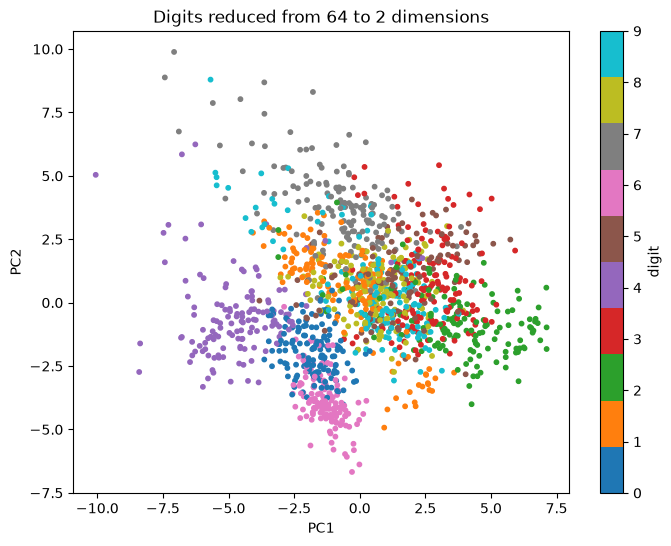

Variance kept by 2 components: 0.218


In [6]:
pca2 = PCA(n_components=2)
X_2d = pca2.fit_transform(X_train)

plt.figure(figsize=(8, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_train, cmap="tab10", s=10)
plt.colorbar(label="digit")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Digits reduced from 64 to 2 dimensions")
plt.show()

print("Variance kept by 2 components:", round(pca2.explained_variance_ratio_.sum(), 3))

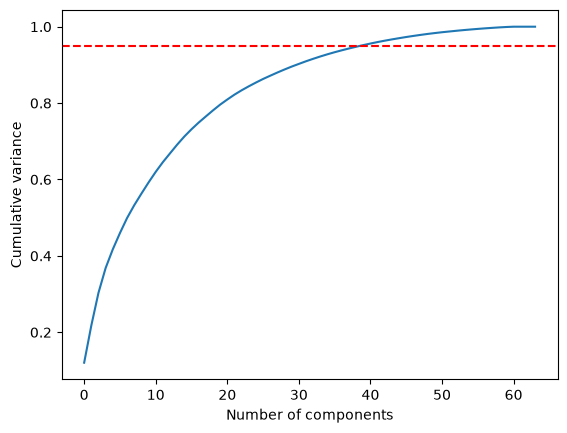

In [7]:

# How much variance do the components keep?
full = PCA().fit(X_train)
plt.plot(full.explained_variance_ratio_.cumsum())
plt.axhline(0.95, color="red", linestyle="--")
plt.xlabel("Number of components")
plt.ylabel("Cumulative variance")
plt.show()